# Walkthrough: weekday-seasonal forecaster

The pieces behind `scripts/run_pipeline.py`, with charts:

1. **The data:** simulated daily payment volume, built from known parts.
2. **What the model learns:** weekday and payday factors, estimated vs true.
3. **One forecast:** the three models side by side for 30 days.
4. **The backtest:** a year of walk-forward forecasts, and where each model goes wrong.

All core logic lives in `src/`; this notebook only calls it. For the full method with formulas, see the [methodology notebook](methodology.ipynb). This model is the base forecast that [Project 2: cash-flow forecaster](https://github.com/marlondocouto2/cash-flow-forecaster) builds on.

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from weekday_seasonal_forecaster import generate_daily_flows, SeasonalWeekday, NaiveWeekly, MovingAverage
from weekday_seasonal_forecaster.data import TRUE_WEEKDAY_FACTORS
from weekday_seasonal_forecaster.features import month_bucket
from weekday_seasonal_forecaster.evaluate import walk_forward, results_table, error_by_weekday
from weekday_seasonal_forecaster import plots   # also sets the chart style
from weekday_seasonal_forecaster.plots import COLORS, INK, INK_2, GRID

def millions(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v/1e6:,.0f}M'))

## 1. The data
Five years of daily outgoing payment volume, the product of known parts: trend x weekday x payday x annual x noise. Each part is kept as a column, so we can check what the model recovers.

In [2]:
df = generate_daily_flows('2021-01-01', '2025-12-31', seed=42)
df.head(8)

,date,volume,trend,weekday_factor,month_factor,annual_factor,noise
0,2021-01-01,7.870364e+07,5.000000e+07,1.286765,1.25,0.960894,1.018451
1,2021-01-02,4.165596e+07,5.001914e+07,0.823529,1.12,0.961044,0.939508
2,2021-01-03,3.806716e+07,5.003828e+07,0.720588,1.05,0.961206,1.046056
3,2021-01-04,5.765729e+07,5.005743e+07,1.132353,1.00,0.961380,1.058057
4,2021-01-05,4.409231e+07,5.007659e+07,1.029412,1.00,0.961565,0.889530
5,2021-01-06,4.357616e+07,5.009575e+07,0.977941,1.00,0.961761,0.924843
6,2021-01-07,5.000901e+07,5.011493e+07,1.029412,1.00,0.961968,1.007700
7,2021-01-08,6.090479e+07,5.013411e+07,1.286765,1.00,0.962187,0.981204


The full series. Growth of 15% a year, a strong weekly rhythm that shows up as a thick band, and a peak every December.

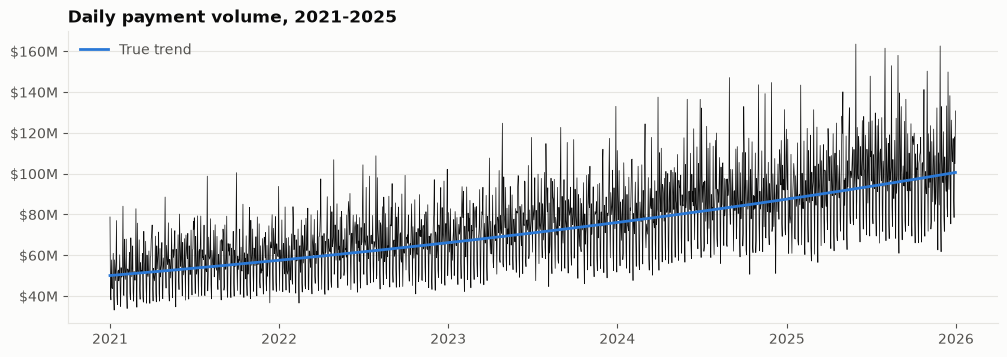

In [3]:
s = df.set_index('date')
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(s.index, s.volume, color=INK, lw=0.5)
ax.plot(s.index, s.trend, color=COLORS['SeasonalWeekday'], lw=2, label='True trend')
ax.set_title('Daily payment volume, 2021-2025')
ax.legend(loc='upper left')
millions(ax)

Zooming in on six weeks shows the two shapes the model is built around: Fridays are high and weekends low every week, and paydays (the 1st, the 15th and the last business day, shaded) lift volume on fixed days of the month.

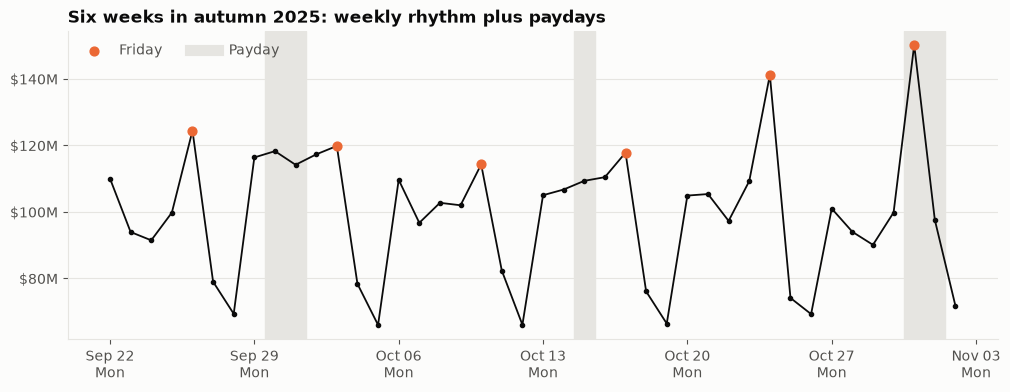

In [4]:
w = s.loc['2025-09-22':'2025-11-02']
fig, ax = plt.subplots(figsize=(12, 4))
pay = w.month_factor >= 1.2
for d in w.index[pay]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=GRID, zorder=0)
ax.plot(w.index, w.volume, color=INK, lw=1.3, marker='o', ms=3, zorder=3)
fri = w.index.day_of_week == 4
ax.scatter(w.index[fri], w.volume[fri], color=COLORS['NaiveWeekly'], s=40, zorder=4, label='Friday')
ax.plot([], [], color=GRID, lw=8, label='Payday')
ax.xaxis.set_major_locator(plt.matplotlib.dates.WeekdayLocator(byweekday=plt.matplotlib.dates.MO))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %d\n%a'))
ax.set_title('Six weeks in autumn 2025: weekly rhythm plus paydays')
ax.legend(loc='upper left', ncols=2)
millions(ax)

## 2. What the model learns
The seasonal model is fitted on all five years (the backtest below refits it every day). It estimates weekday factors from the last 12 weeks and payday factors from the last year, then a level from the last 28 days.

In [5]:
model = SeasonalWeekday().fit(df)
print(f'level: ${model.level_/1e6:.1f}M a day (deseasonalized average of the last 28 days)')

level: $105.0M a day (deseasonalized average of the last 28 days)


Estimated vs true factors. The weekday factors land within a few percent of the truth. The payday factors are averages over each bucket, so they smooth single-day lifts: the 1st of the month is x1.25 in the data, but its bucket (days 1-3) averages about x1.1.

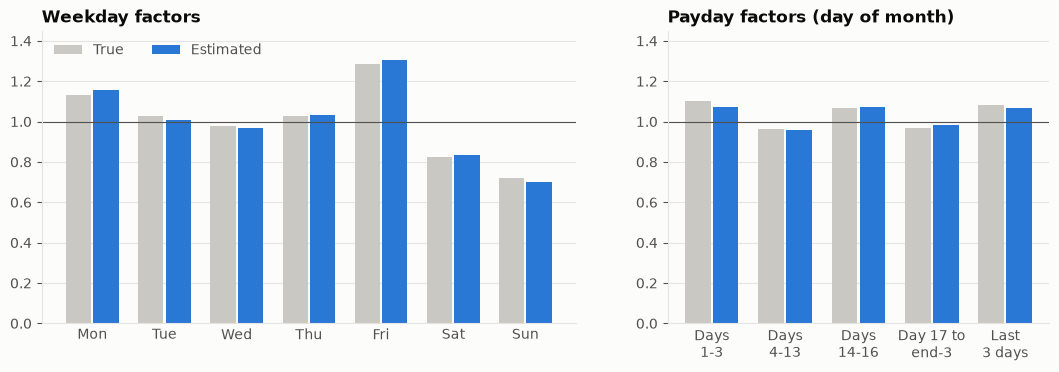

In [6]:
t = s.month_factor.loc['2025']
true_month = t.groupby(month_bucket(t.index).values).mean() / t.mean()
buckets = ['d01_03', 'd04_13', 'd14_16', 'd17_late', 'last3']
blabels = ['Days\n1-3', 'Days\n4-13', 'Days\n14-16', 'Day 17 to\nend-3', 'Last\n3 days']

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[7, 5])
x = np.arange(7); w_ = 0.38
a1.bar(x - w_/2, TRUE_WEEKDAY_FACTORS, w_ * 0.92, color='#c9c8c2', label='True', zorder=2)
a1.bar(x + w_/2, model.weekday_factors_.values, w_ * 0.92, color=COLORS['SeasonalWeekday'], label='Estimated', zorder=2)
a1.set_xticks(x, ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']); a1.tick_params(axis='x', length=0)
a1.set_title('Weekday factors'); a1.set_ylim(0, 1.45); a1.axhline(1, color=INK_2, lw=0.8)
a1.legend(ncols=2, loc='upper left')
x = np.arange(5)
a2.bar(x - w_/2, true_month.reindex(buckets), w_ * 0.92, color='#c9c8c2', zorder=2)
a2.bar(x + w_/2, model.month_factors_.reindex(buckets), w_ * 0.92, color=COLORS['SeasonalWeekday'], zorder=2)
a2.set_xticks(x, blabels); a2.tick_params(axis='x', length=0)
a2.set_title('Payday factors (day of month)'); a2.set_ylim(0, 1.45); a2.axhline(1, color=INK_2, lw=0.8);

## 3. One forecast, three models
All three models fitted on data up to 30 September 2025, forecasting the next 30 days. `NaiveWeekly` repeats last week, `MovingAverage` is a flat line, and `SeasonalWeekday` reproduces the weekly and payday shape.

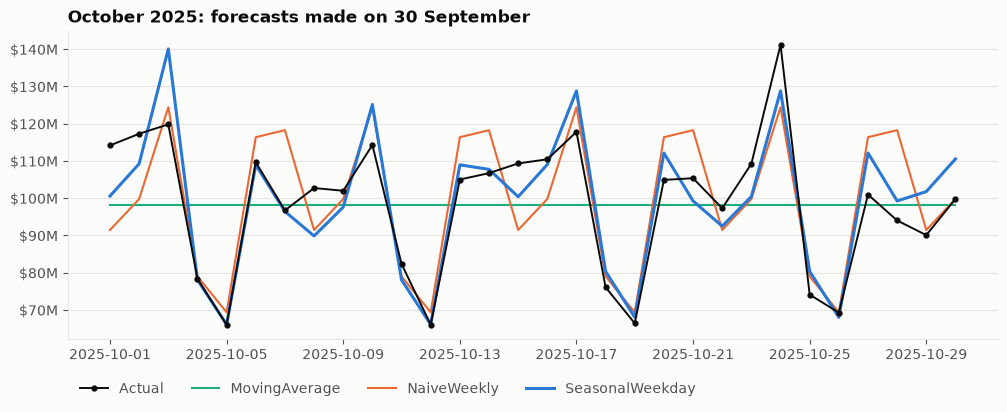

In [7]:
origin = '2025-09-30'
train = df[df.date <= origin][['date', 'volume']]
dates = pd.date_range('2025-10-01', periods=30)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, s.volume.reindex(dates), color=INK, lw=1.4, marker='o', ms=3.5, label='Actual', zorder=4)
for cls in (MovingAverage, NaiveWeekly, SeasonalWeekday):
    m = cls().fit(train)
    ax.plot(dates, m.predict(dates), color=COLORS[m.name], lw=2.2 if m.name == 'SeasonalWeekday' else 1.5,
            label=m.name, zorder=3 if m.name == 'SeasonalWeekday' else 2)
ax.set_title('October 2025: forecasts made on 30 September')
ax.legend(ncols=4, loc='upper left', bbox_to_anchor=(0, -0.1))
millions(ax)

## 4. The backtest
A year of walk-forward forecasts (2025). At every day, each model is refit on data up to that day only, and forecasts 1, 7 and 30 days ahead. It takes a few seconds.

In [8]:
bt = pd.concat([walk_forward(df, m) for m in (NaiveWeekly, MovingAverage, SeasonalWeekday)], ignore_index=True)
results = results_table(bt)
show = results.copy()
for c in ['MAE', 'RMSE', 'required_buffer']:
    show[c] = (show[c] / 1e6).round(2)
show['MAPE'] = show['MAPE'].round(1)
show.drop(columns=['MSE'])

,model,horizon,n,MAE,RMSE,MAPE,required_buffer
0,SeasonalWeekday,1,365,6.77,8.87,6.8,15.66
1,NaiveWeekly,1,365,10.24,14.33,10.1,26.52
2,MovingAverage,1,365,15.86,20.22,17.2,34.15
3,SeasonalWeekday,7,365,6.69,8.69,6.7,15.80
4,NaiveWeekly,7,365,10.24,14.33,10.1,26.52
5,MovingAverage,7,365,15.77,20.07,17.1,33.81
6,SeasonalWeekday,30,365,6.82,8.75,6.9,15.39
7,NaiveWeekly,30,365,10.59,14.27,10.5,25.69
8,MovingAverage,30,365,16.03,20.25,17.2,34.20


Average error and the required cash buffer (the 95th percentile of shortfalls) by horizon. The seasonal model needs about $11M a day less buffer than the naive rule, and its accuracy barely changes from 1 to 30 days ahead.

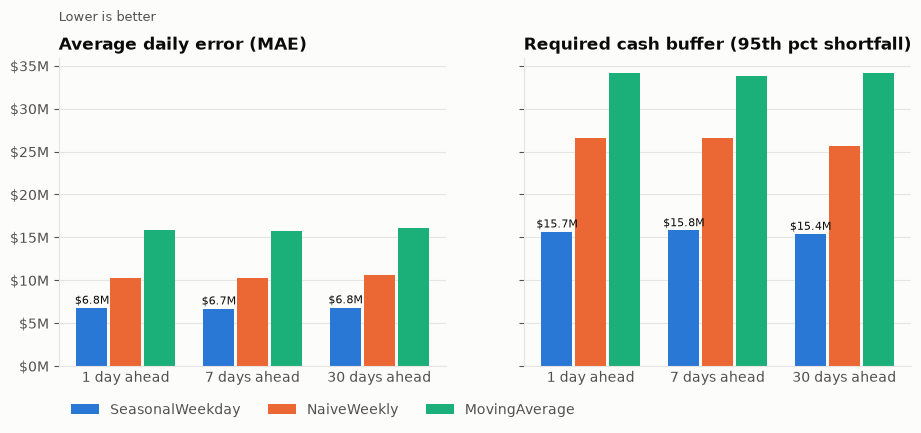

In [9]:
plots.plot_headline(results, None)

The last quarter of 2025, 7 days ahead. The moving average stays flat; the naive forecast repeats last week's noise; the seasonal model follows the shape. Note the end of December: there is no yearly component, so the seasonal model under-forecasts the December peak.

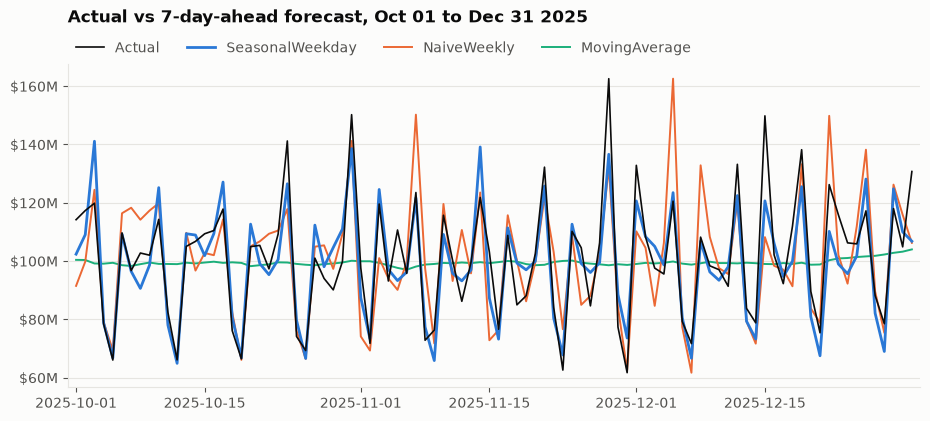

In [10]:
plots.plot_actual_vs_forecast(bt, 7, '2025-10-01', '2025-12-31', None)

Where each model goes wrong. The moving average fails on Fridays and weekends, the days furthest from average. The naive rule is worst on Fridays and Mondays, where paydays move around. The seasonal model's error is low and even across the week.

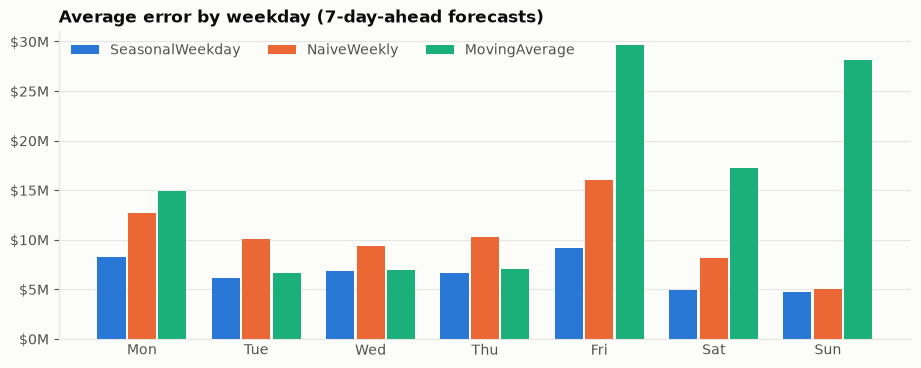

In [11]:
plots.plot_error_by_weekday(error_by_weekday(bt), 7, None)